# Fine-tuning YOLOv8m per il rilevamento dei giocatori

Notebook separato per object detection di persone/giocatori tramite bounding box. Non implementa tracking, squadre, ruoli, pose o lettura dei numeri di maglia. Il checkpoint COCO iniziale riconosce la classe `person`, che puo includere anche arbitri e spettatori: per distinguerli serve un dataset volley annotato in modo coerente.

Un candidato mirato e [Tracking Volleyball Players di David Paulinus](https://universe.roboflow.com/david-paulinus-54fnl/tracking-volleyball-players), pubblicato con licenza CC BY 4.0: la pagina segnala classi `player` e `refree` (referee, scritto cosi nel dataset). La quantita dipende dalla versione esportata (circa 1.6k immagini e 6 versioni; la versione 2 mostrata ha 1275 immagini). Un secondo candidato, [Volleyball Player](https://universe.roboflow.com/yan-personal-dataset/volleyball-player), e molto piu piccolo (125 immagini), con classi `person` e `sports ball`, licenza CC BY 4.0. Sono fonti da valutare, non garanzie di qualita; rispettare attribuzione/licenza e verificare la versione scelta. Nessuno dei due e scaricato da questo notebook.

Il notebook conserva classi e label del dataset cosi come sono. Nel candidato a due classi, `player` e `refree` restano classi separate: non si usa `single_cls=True`, non si converte l'arbitro in giocatore e le metriche vengono mostrate per ogni classe. Il dataset locale dei palloni non e usato.

## Configurazione e dataset locale

Scarica/esporta manualmente una versione YOLO detection del dataset scelto e verifica la licenza prima di copiarla in locale. Poi imposta `DATASET_DIR` sulla cartella che contiene `data.yaml`, `train/images`, `train/labels`, `valid/images` e, facoltativamente, `test/images` e `test/labels`. Gli split non vengono spostati o modificati. Se il dataset non c'e, il preflight si ferma con un messaggio; non crea dati o metriche dimostrative.

In [5]:
from pathlib import Path
from datetime import datetime
import json
import math
import sys

try:
    import yaml
except ImportError as exc:
    raise ModuleNotFoundError("PyYAML non e installato nell'interprete del kernel corrente.") from exc

WORKSPACE_DIR = next(
    (p.resolve() for p in (Path.cwd(), *Path.cwd().parents)
     if (p / "Annotazioni").is_dir() and (p / "runs" / "volleyball_ball").is_dir()),
    None,
)
if WORKSPACE_DIR is None:
    raise FileNotFoundError("Avvia il notebook dalla cartella di lavoro Scout_Volley_CV&NLP o da una sua sottocartella.")

# Inserisci la cartella dell'export giocatori. None cerca una sola cartella locale con data.yaml e classe player.
DATASET_DIR = WORKSPACE_DIR / "Tracking Volleyball Players.v2i.yolov8"
DATA_YAML_NAME = "data.yaml"
TRAIN_IMAGES_RELATIVE = Path("train/images")
TRAIN_LABELS_RELATIVE = Path("train/labels")
VAL_IMAGES_RELATIVE = Path("valid/images")
VAL_LABELS_RELATIVE = Path("valid/labels")
TEST_IMAGES_RELATIVE = Path("test/images")
TEST_LABELS_RELATIVE = Path("test/labels")
PLAYER_CLASS_NAME = "player"  # il controllo ignora maiuscole/minuscole ma non rinomina classi

# Checkpoint COCO locale verificato nella cartella di lavoro; non usa pesi palla e non scarica da Internet.
PRETRAINED_WEIGHTS_PATH = WORKSPACE_DIR / "yolov8m.pt"
EPOCHS = 100
PATIENCE = 20
IMAGE_SIZE = 640
GPU_BATCH_SIZE = 16
CPU_BATCH_SIZE = 2
WORKERS = 0  # compatibilita Windows/Jupyter
SEED = 42
SAMPLE_COUNT = 4
OUTPUT_ROOT = WORKSPACE_DIR / "runs" / "volleyball_players"

if DATASET_DIR is None:
    candidates = []
    for folder in WORKSPACE_DIR.iterdir():
        yaml_path = folder / DATA_YAML_NAME if folder.is_dir() else None
        if yaml_path is not None and yaml_path.is_file():
            try:
                candidate_data = yaml.safe_load(yaml_path.read_text(encoding="utf-8")) or {}
                candidate_names = candidate_data.get("names", [])
                if isinstance(candidate_names, dict):
                    candidate_names = list(candidate_names.values())
                if any(str(name).strip().lower() == PLAYER_CLASS_NAME for name in candidate_names):
                    candidates.append(folder.resolve())
            except (OSError, ValueError, TypeError, yaml.YAMLError):
                continue
    if len(candidates) == 1:
        DATASET_DIR = candidates[0]
    elif len(candidates) > 1:
        raise ValueError(f"Trovati piu dataset con classe {PLAYER_CLASS_NAME!r}: {candidates}. Imposta DATASET_DIR esplicitamente.")
    else:
        DATASET_DIR = WORKSPACE_DIR / "dataset_giocatori"

DATASET_DIR = Path(DATASET_DIR).expanduser()
if not DATASET_DIR.is_absolute():
    DATASET_DIR = WORKSPACE_DIR / DATASET_DIR
DATASET_DIR = DATASET_DIR.resolve()
if not (DATASET_DIR / DATA_YAML_NAME).is_file():
    raise FileNotFoundError(
        f"Dataset giocatori non trovato: {DATASET_DIR}. Nella cartella di lavoro e presente solo il dataset palloni, "
        "che questo notebook non riutilizza. Candidati da esportare manualmente: "
        "Tracking Volleyball Players (CC BY 4.0, classi player/refree) oppure Volleyball Player (CC BY 4.0, piccolo). "
        "Verifica la licenza/versione, imposta DATASET_DIR e riesegui questa cella. Nessun dataset e stato scaricato."
    )
print(f"Workspace: {WORKSPACE_DIR}\nDataset giocatori: {DATASET_DIR}\nOutput: {OUTPUT_ROOT}")
print(f"Split configurati: train={TRAIN_IMAGES_RELATIVE}, val={VAL_IMAGES_RELATIVE}, test opzionale={TEST_IMAGES_RELATIVE}")

Workspace: C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP
Dataset giocatori: C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\Tracking Volleyball Players.v2i.yolov8
Output: C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\runs\volleyball_players
Split configurati: train=train\images, val=valid\images, test opzionale=test\images


## Dipendenze e preflight CUDA/NMS

Il notebook non installa o aggiorna pacchetti nel kernel corrente. PyTorch, torchvision e Ultralytics devono essere gia disponibili. Il test NMS CPU e CUDA rileva problemi reali prima del training; in assenza di CUDA o se manca solo NMS CUDA, seleziona esplicitamente CPU. Errori diversi da una NMS CUDA non supportata non vengono nascosti. In caso di ambiente incompatibile, usa un ambiente virtuale/kernel Jupyter isolato.

In [6]:
import importlib.util
missing = [name for name in ("torch", "torchvision", "ultralytics", "yaml", "PIL", "matplotlib", "pandas")
           if importlib.util.find_spec(name) is None]
if missing:
    raise ModuleNotFoundError(f"Dipendenze mancanti nel kernel {sys.executable}: {missing}. Installale in un ambiente isolato e riavvia il kernel.")

import torch
import torchvision
from ultralytics import YOLO

def run_nms_smoke_test(device):
    boxes = torch.tensor([[0., 0., 10., 10.], [1., 1., 11., 11.]], device=device)
    scores = torch.tensor([0.9, 0.8], device=device)
    kept = torchvision.ops.nms(boxes, scores, 0.5).tolist()
    if kept != [0]:
        raise RuntimeError(f"Risultato NMS inatteso su {device}: {kept}")

print(f"Interprete: {sys.executable}; Python {sys.version.split()[0]}; torch {torch.__version__}; torchvision {torchvision.__version__}; CUDA build {torch.version.cuda}")
run_nms_smoke_test("cpu")
CUDA_AVAILABLE = bool(torch.cuda.is_available())
if CUDA_AVAILABLE:
    try:
        run_nms_smoke_test("cuda:0")
    except NotImplementedError as exc:
        message = str(exc)
        if "torchvision::nms" not in message or "CUDA" not in message:
            raise
        CUDA_AVAILABLE = False
        print("NMS CUDA non disponibile in torchvision: fallback CPU esplicito.")
    else:
        print(f"NMS CPU/CUDA: OK; GPU {torch.cuda.get_device_name(0)}")
if CUDA_AVAILABLE:
    DEVICE, BATCH_SIZE = 0, GPU_BATCH_SIZE
else:
    DEVICE, BATCH_SIZE = "cpu", CPU_BATCH_SIZE
    print("CUDA non disponibile o non richiesta: training/inferenza su CPU.")
    if torch.version.cuda is None:
        print("Diagnostica: PyTorch CPU-only; per GPU serve una build CUDA compatibile in un ambiente/kernel separato.")
    else:
        print("Diagnostica: PyTorch CUDA presente ma GPU non utilizzabile; verificare driver/runtime e accesso GPU.")
print(f"Dispositivo selezionato: {DEVICE}; batch={BATCH_SIZE}; workers={WORKERS}")

Interprete: c:\Users\SavarDar\AppData\Local\Programs\Python\Python314\python.exe; Python 3.14.6; torch 2.14.1+cu130; torchvision 0.29.1+cu130; CUDA build 13.0
NMS CPU/CUDA: OK; GPU NVIDIA RTX PRO 2000 Blackwell Generation Laptop GPU
Dispositivo selezionato: 0; batch=16; workers=0


## Verifica checkpoint pretrained locale

Il file `yolov8m.pt` locale e un checkpoint COCO detection (80 classi, `person` a indice 0). Viene controllato caricando il modello dal percorso locale; non si tenta un download se il file manca. Questo e il pretraining generico iniziale, non il checkpoint del detector palloni.

In [7]:
configured_weights = Path(PRETRAINED_WEIGHTS_PATH).expanduser()
if not configured_weights.is_absolute():
    configured_weights = WORKSPACE_DIR / configured_weights
if not configured_weights.is_file():
    raise FileNotFoundError(f"Checkpoint COCO locale mancante: {configured_weights}. Indica un checkpoint YOLO detection locale; non viene effettuato alcun download.")
if configured_weights.stat().st_size == 0:
    raise ValueError(f"Il checkpoint pretrained e vuoto: {configured_weights}")
RESOLVED_WEIGHTS = configured_weights.resolve()
pretrained_model = YOLO(str(RESOLVED_WEIGHTS))
if pretrained_model.task != "detect":
    raise ValueError(f"Checkpoint non detection: task={pretrained_model.task!r}")
pretrained_names = pretrained_model.names
person_indices = [i for i, name in (pretrained_names.items() if isinstance(pretrained_names, dict) else enumerate(pretrained_names))
                  if str(name).strip().lower() == "person"]
if not person_indices:
    raise ValueError(f"Checkpoint senza classe person: {pretrained_names}")
print(f"Checkpoint: {RESOLVED_WEIGHTS} ({RESOLVED_WEIGHTS.stat().st_size:,} byte)")
print(f"Task={pretrained_model.task}; classi={len(pretrained_names)}; person index={person_indices}")
del pretrained_model

Checkpoint: C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\yolov8m.pt (52,136,884 byte)
Task=detect; classi=80; person index=[0]


## Preflight split, classi e label YOLO

Train e validation sono obbligatori; test e facoltativo e, se presente e valido, resta separato fino alla valutazione finale. Il controllo verifica file immagini/label, formato detection YOLO a 5 campi, indici classe, coordinate normalizzate e distribuzioni per classe. Le label originali non vengono riscritte. Le immagini senza oggetti possono usare un `.txt` vuoto; il matching dei file si basa sul nome senza estensione.

In [8]:
from collections import Counter
from PIL import Image
import numpy as np

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
source_yaml = yaml.safe_load((DATASET_DIR / DATA_YAML_NAME).read_text(encoding="utf-8")) or {}
raw_names = source_yaml.get("names")
if isinstance(raw_names, list):
    CLASS_NAMES = [str(x) for x in raw_names]
elif isinstance(raw_names, dict):
    try:
        CLASS_NAMES = [str(raw_names[k] if k in raw_names else raw_names[str(k)]) for k in range(len(raw_names))]
    except KeyError as exc:
        raise ValueError(f"data.yaml names deve avere indici contigui da 0: {raw_names}") from exc
else:
    raise ValueError("data.yaml deve dichiarare names come lista o mapping di classi")
declared_nc = source_yaml.get("nc")
if declared_nc is not None and int(declared_nc) != len(CLASS_NAMES):
    raise ValueError(f"data.yaml dichiara nc={declared_nc}, ma names contiene {len(CLASS_NAMES)} classi: {CLASS_NAMES}")
if not CLASS_NAMES or len({name.strip().lower() for name in CLASS_NAMES}) != len(CLASS_NAMES):
    raise ValueError(f"Nomi classi vuoti o duplicati: {CLASS_NAMES}")
player_ids = [i for i, name in enumerate(CLASS_NAMES) if name.strip().lower() == PLAYER_CLASS_NAME]
if len(player_ids) != 1:
    raise ValueError(f"Attesa esattamente una classe {PLAYER_CLASS_NAME!r}; nomi trovati: {CLASS_NAMES}. Correggi il dataset/config esplicitamente, non rinominare labels automaticamente.")
print("Classi originali (indice -> nome):", dict(enumerate(CLASS_NAMES)))
print(f"Classe giocatore per metriche dedicate: {player_ids[0]} -> {CLASS_NAMES[player_ids[0]]!r}")
if any(name.strip().lower() in {"refree", "referee"} for name in CLASS_NAMES):
    print("Classe arbitro presente e mantenuta separata: non sara assimilata ai giocatori.")
print("Importante: 'player' dipende dalle annotazioni del dataset; non garantisce di distinguere arbitri/spettatori se non etichettati come classi separate.")

def inspect_split(name, image_relative, label_relative, required):
    images_dir, labels_dir = DATASET_DIR / image_relative, DATASET_DIR / label_relative
    if not images_dir.is_dir() or not labels_dir.is_dir():
        return {"name": name, "valid": False, "reason": f"manca {images_dir} o {labels_dir}", "images": [], "counts": Counter(), "boxes": 0}
    images = sorted(p for p in images_dir.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS)
    label_files = {p.relative_to(labels_dir).with_suffix("").as_posix(): p for p in labels_dir.rglob("*.txt")}
    errors, counts, boxes = [], Counter(), 0
    image_keys = {p.relative_to(images_dir).with_suffix("").as_posix() for p in images}
    missing_labels = image_keys - set(label_files)
    orphan_labels = set(label_files) - image_keys
    if not images:
        errors.append("nessuna immagine")
    if missing_labels:
        errors.append(f"{len(missing_labels)} immagini senza label txt")
    if orphan_labels:
        errors.append(f"{len(orphan_labels)} label senza immagine")
    empty_images = 0
    for key in sorted(image_keys & set(label_files)):
        path = label_files[key]
        line_number = 0
        try:
            for line_number, line in enumerate(path.read_text(encoding="utf-8").splitlines(), 1):
                fields = line.split()
                if len(fields) != 5:
                    raise ValueError(f"attesi 5 campi detection YOLO, ricevuti {len(fields)}")
                class_value = float(fields[0])
                values = np.asarray([float(x) for x in fields[1:]], dtype=np.float64)
                if not math.isfinite(class_value) or not class_value.is_integer():
                    raise ValueError("class id non intero")
                class_id = int(class_value)
                if class_id < 0 or class_id >= len(CLASS_NAMES):
                    raise ValueError(f"class id {class_id} fuori da 0..{len(CLASS_NAMES)-1}")
                if not np.isfinite(values).all() or np.any(values < 0) or np.any(values > 1):
                    raise ValueError("coordinate/dimensioni devono essere finite e normalizzate in [0,1]")
                if values[2] <= 0 or values[3] <= 0:
                    raise ValueError("larghezza/altezza bbox devono essere positive")
                counts[class_id] += 1
                boxes += 1
        except (OSError, ValueError) as exc:
            errors.append(f"{path.name}:{line_number or '?'}: {exc}")
            break
        if path.stat().st_size == 0:
            empty_images += 1
    valid = not errors
    return {"name": name, "valid": valid, "reason": "; ".join(errors), "images": images,
            "counts": counts, "boxes": boxes, "empty_images": empty_images}

splits = {
    "train": inspect_split("train", TRAIN_IMAGES_RELATIVE, TRAIN_LABELS_RELATIVE, True),
    "valid": inspect_split("valid", VAL_IMAGES_RELATIVE, VAL_LABELS_RELATIVE, True),
}
test_candidate = inspect_split("test", TEST_IMAGES_RELATIVE, TEST_LABELS_RELATIVE, False)
TEST_VALID = bool(test_candidate["valid"])
splits["test"] = test_candidate
for split_name in ("train", "valid", "test"):
    info = splits[split_name]
    if split_name in {"train", "valid"} and not info["valid"]:
        raise ValueError(f"Split obbligatorio {split_name} non valido: {info['reason']}")
    if split_name == "test" and not info["valid"]:
        print(f"Test escluso (facoltativo): {info['reason']}")
        continue
    print(f"{split_name}: {len(info['images'])} immagini; {info['boxes']} box; per classe "
          f"{ {CLASS_NAMES[k]: info['counts'][k] for k in range(len(CLASS_NAMES))} }")
if splits["train"]["boxes"] == 0 or splits["valid"]["boxes"] == 0:
    raise ValueError("Train e validation devono contenere almeno un bounding box valido.")
if TEST_VALID and splits["test"]["boxes"] == 0:
    TEST_VALID = False
    print("Test escluso: split senza bounding box validi.")
if splits["train"]["counts"][player_ids[0]] == 0:
    raise ValueError("Nessun bounding box della classe player nel train.")
if splits["valid"]["counts"][player_ids[0]] == 0:
    raise ValueError("Nessun bounding box della classe player nella validation.")

Classi originali (indice -> nome): {0: 'player', 1: 'refree'}
Classe giocatore per metriche dedicate: 0 -> 'player'
Classe arbitro presente e mantenuta separata: non sara assimilata ai giocatori.
Importante: 'player' dipende dalle annotazioni del dataset; non garantisce di distinguere arbitri/spettatori se non etichettati come classi separate.
train: 1155 immagini; 15152 box; per classe {'player': 12217, 'refree': 2935}
valid: 330 immagini; 4350 box; per classe {'player': 3517, 'refree': 833}
test: 164 immagini; 2148 box; per classe {'player': 1732, 'refree': 416}


## YAML di training e anteprima label

Viene creato un YAML derivato nella cartella output, con tutte le classi originali e percorsi assoluti. Il dataset e i file label restano invariati. L'anteprima mostra box e nome classe per controllare che giocatore e arbitro non siano confusi.

path: C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\Tracking
  Volleyball Players.v2i.yolov8
train: train/images
val: valid/images
nc: 2
names:
  0: player
  1: refree
test: test/images



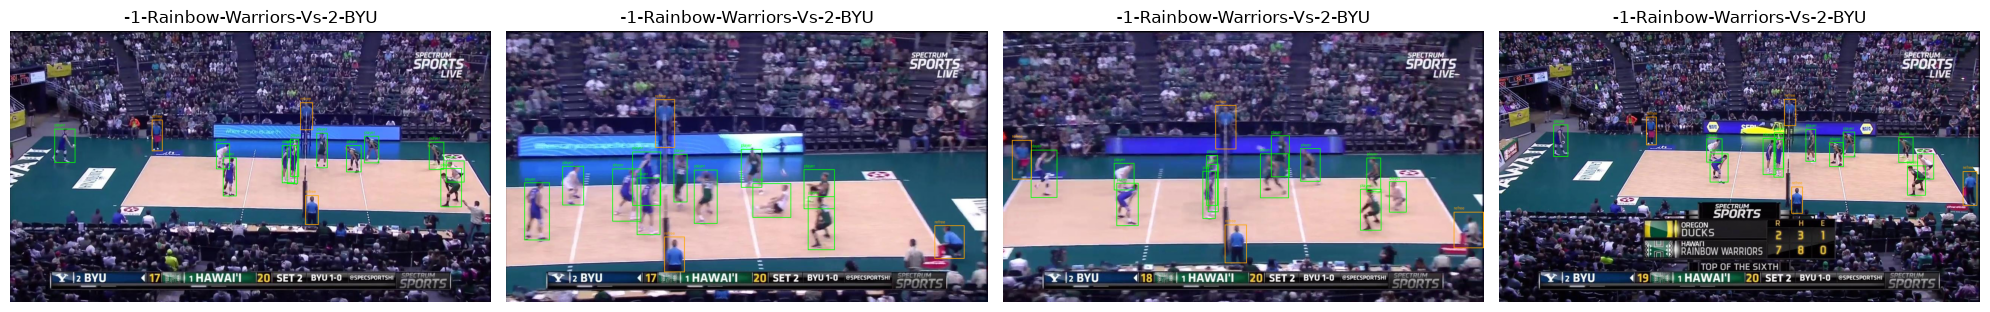

In [9]:
dataset_config = {
    "path": str(DATASET_DIR),
    "train": TRAIN_IMAGES_RELATIVE.as_posix(),
    "val": VAL_IMAGES_RELATIVE.as_posix(),
    "nc": len(CLASS_NAMES),
    "names": {i: name for i, name in enumerate(CLASS_NAMES)},
}
if TEST_VALID:
    dataset_config["test"] = TEST_IMAGES_RELATIVE.as_posix()
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
DATA_YAML = OUTPUT_ROOT / "dataset_giocatori_yolov8.yaml"
DATA_YAML.write_text(yaml.safe_dump(dataset_config, sort_keys=False, allow_unicode=True), encoding="utf-8")
print(DATA_YAML.read_text(encoding="utf-8"))

import matplotlib.pyplot as plt
from PIL import ImageDraw
sample_images = splits["train"]["images"][:max(1, min(SAMPLE_COUNT, len(splits["train"]["images"]))) ]
fig, axes = plt.subplots(1, len(sample_images), figsize=(5 * len(sample_images), 4))
if len(sample_images) == 1:
    axes = [axes]
for ax, image_path in zip(axes, sample_images):
    image = Image.open(image_path).convert("RGB")
    draw = ImageDraw.Draw(image)
    label_path = DATASET_DIR / TRAIN_LABELS_RELATIVE / image_path.relative_to(DATASET_DIR / TRAIN_IMAGES_RELATIVE).with_suffix(".txt")
    width, height = image.size
    if label_path.is_file():
        for line in label_path.read_text(encoding="utf-8").splitlines():
            cls, xc, yc, bw, bh = map(float, line.split())
            x1, y1 = (xc-bw/2)*width, (yc-bh/2)*height
            x2, y2 = (xc+bw/2)*width, (yc+bh/2)*height
            name = CLASS_NAMES[int(cls)]
            color = "lime" if int(cls) == player_ids[0] else "orange"
            draw.rectangle((x1, y1, x2, y2), outline=color, width=max(2, width//500))
            draw.text((x1, max(0, y1-16)), name, fill=color)
    ax.imshow(image)
    ax.set_title(image_path.name[:28])
    ax.axis("off")
plt.tight_layout()
plt.show()

## Fine-tuning

Il training valida a ogni epoca sullo split `valid`; `best.pt` e scelto con validation. Non si applica `single_cls` ne si filtrano/riscrivono le classi: anche eventuali classi arbitro restano supervisionate separatamente. La qualita dipende dalla versione dataset e dalla separazione dei video: evita di avere frame quasi identici dello stesso video in split diversi.

In [10]:
RUN_NAME = "yolov8m_players_" + datetime.now().strftime("%Y%m%d_%H%M%S")
model = YOLO(str(RESOLVED_WEIGHTS))
train_results = model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    patience=PATIENCE,
    imgsz=IMAGE_SIZE,
    batch=BATCH_SIZE,
    workers=WORKERS,
    device=DEVICE,
    project=str(OUTPUT_ROOT),
    name=RUN_NAME,
    exist_ok=False,
    pretrained=True,
    seed=SEED,
    cache=False,
    plots=True,
    verbose=True,
)
TRAIN_RUN_DIR = Path(model.trainer.save_dir)
BEST_WEIGHTS = Path(model.trainer.best)
if not BEST_WEIGHTS.is_file():
    raise FileNotFoundError(f"Checkpoint best non trovato: {BEST_WEIGHTS}")
print(f"Best checkpoint: {BEST_WEIGHTS}\nRisultati training: {TRAIN_RUN_DIR}")

New https://pypi.org/project/ultralytics/8.4.215 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.212  Python-3.14.6 torch-2.14.1+cu130 CUDA:0 (NVIDIA RTX PRO 2000 Blackwell Generation Laptop GPU, 8151MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\runs\volleyball_players\dataset_giocatori_yolov8.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640,

## Valutazione: precision, recall e mAP per classe

La validation descrive il checkpoint scelto senza usare il test per selezionarlo. Se lo split test e valido, viene valutato una sola volta dopo la validation. Le metriche sono di object detection; `mAP50` e `mAP50-95` non sono accuracy di classificazione. Oltre al riepilogo complessivo sono riportati i valori per `player` e per ogni altra classe (ad esempio `refree`). Nessuna metrica viene precompilata.

In [11]:
import pandas as pd
best_model = YOLO(str(BEST_WEIGHTS))

def evaluate_split(split_name, eval_name):
    result = best_model.val(
        data=str(DATA_YAML), split=split_name, imgsz=IMAGE_SIZE,
        batch=BATCH_SIZE, workers=WORKERS, device=DEVICE,
        project=str(OUTPUT_ROOT), name=eval_name, exist_ok=False,
        plots=True, verbose=True,
    )
    box = result.box
    rows = [{"split": split_name, "classe": "TUTTE (media Ultralytics)",
             "precision": float(box.mp), "recall": float(box.mr),
             "mAP50": float(box.map50), "mAP50-95": float(box.map),
             "immagini": len(splits["valid" if split_name == "val" else split_name]["images"]),
             "checkpoint": str(BEST_WEIGHTS)}]
    present_ids = [int(x) for x in box.ap_class_index.tolist()]
    for class_id, class_name in enumerate(CLASS_NAMES):
        if class_id in present_ids:
            precision, recall, map50, map5095 = box.class_result(present_ids.index(class_id))
            rows.append({"split": split_name, "classe": class_name,
                         "precision": float(precision), "recall": float(recall),
                         "mAP50": float(map50), "mAP50-95": float(map5095),
                         "immagini": len(splits["valid" if split_name == "val" else split_name]["images"]),
                         "checkpoint": str(BEST_WEIGHTS)})
        else:
            rows.append({"split": split_name, "classe": class_name,
                         "precision": float("nan"), "recall": float("nan"),
                         "mAP50": float("nan"), "mAP50-95": float("nan"),
                         "immagini": len(splits["valid" if split_name == "val" else split_name]["images"]),
                         "checkpoint": str(BEST_WEIGHTS), "nota": "classe senza GT nel validation"})
    return rows, result

metric_rows, validation_result = evaluate_split("val", "evaluation_validation")
test_result = None
if TEST_VALID:
    test_rows, test_result = evaluate_split("test", "evaluation_test")
    metric_rows.extend(test_rows)
metrics = pd.DataFrame(metric_rows)
METRICS_CSV = TRAIN_RUN_DIR / "metriche_detection_per_classe.csv"
metrics.to_csv(METRICS_CSV, index=False, float_format="%.6f")
display(metrics.round(4))
print(f"Metriche salvate in: {METRICS_CSV}")
print(f"Metriche giocatore da controllare: classe {CLASS_NAMES[player_ids[0]]!r}; non confondere con la media di tutte le classi.")

Ultralytics 8.4.212  Python-3.14.6 torch-2.14.1+cu130 CUDA:0 (NVIDIA RTX PRO 2000 Blackwell Generation Laptop GPU, 8151MiB)
Model summary (fused): 92 layers, 25,840,918 parameters, 0 gradients, 78.7 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 499.8±202.5 MB/s, size: 194.6 KB)
val: Scanning C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\Tracking Volleyball Players.v2i.yolov8\valid\labels.cache... 330 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 330/330 153.8Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 21/21 3.1it/s 6.9s0.3s
                   all        330       4350      0.987      0.983      0.993      0.735
                player        330       3517      0.985      0.978      0.994      0.726
                refree        327        833      0.988      0.987      0.993      0.744
Speed: 0.1ms preprocess, 7.4ms inference, 0.0ms loss, 1.1ms postprocess per image
Results 

,split,classe,precision,recall,mAP50,mAP50-95,immagini,checkpoint
0,val,TUTTE (media Ultralytics),0.9866,0.9826,0.9934,0.7350,330,C:\Users\SavarDar\OneDrive - Electrolux\Deskto...
1,val,player,0.9854,0.9785,0.9938,0.7258,330,C:\Users\SavarDar\OneDrive - Electrolux\Deskto...
2,val,refree,0.9878,0.9868,0.9929,0.7443,330,C:\Users\SavarDar\OneDrive - Electrolux\Deskto...
3,test,TUTTE (media Ultralytics),0.9880,0.9822,0.9918,0.7371,164,C:\Users\SavarDar\OneDrive - Electrolux\Deskto...
4,test,player,0.9856,0.9740,0.9908,0.7179,164,C:\Users\SavarDar\OneDrive - Electrolux\Deskto...
5,test,refree,0.9905,0.9904,0.9929,0.7563,164,C:\Users\SavarDar\OneDrive - Electrolux\Deskto...


Metriche salvate in: C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\runs\volleyball_players\yolov8m_players_20261117_083439\metriche_detection_per_classe.csv
Metriche giocatore da controllare: classe 'player'; non confondere con la media di tutte le classi.


## Curve e artefatti

Le curve vengono mostrate se generate dalla versione/configurazione Ultralytics in uso. Il notebook salva la tabella delle metriche per classe e un riepilogo riproducibile di dataset, mapping originale, checkpoint, parametri, ambiente e output. I risultati diventano disponibili solo dopo aver eseguito training e valutazione.

C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\runs\volleyball_players\yolov8m_players_20261117_083439\results.png


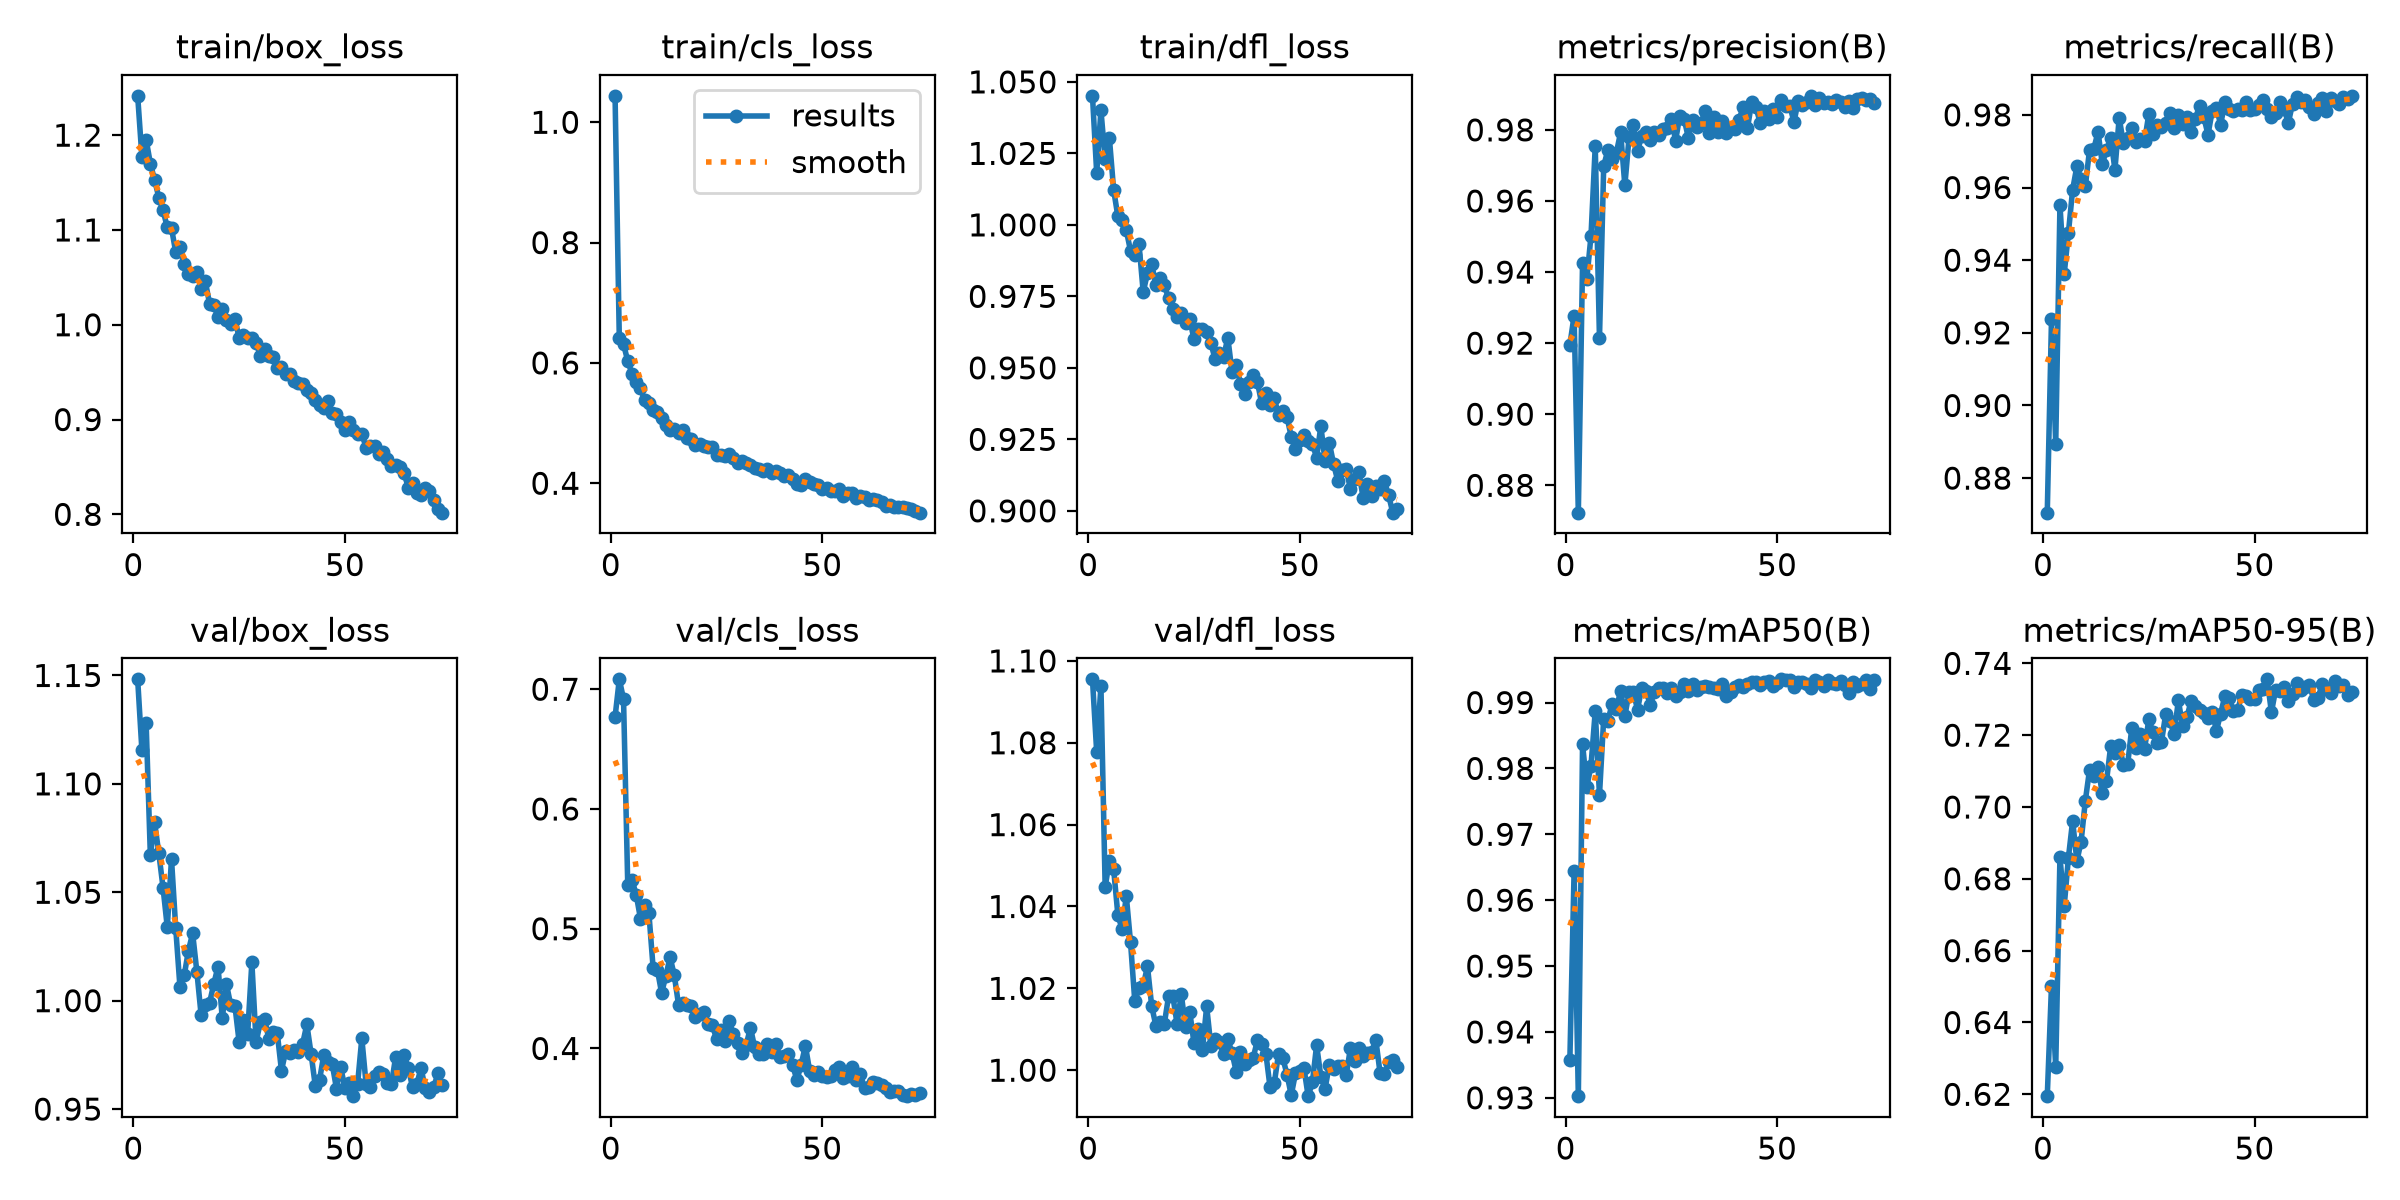

Grafico non generato da questa configurazione: PR_curve.png
C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\runs\volleyball_players\evaluation_validation\confusion_matrix.png


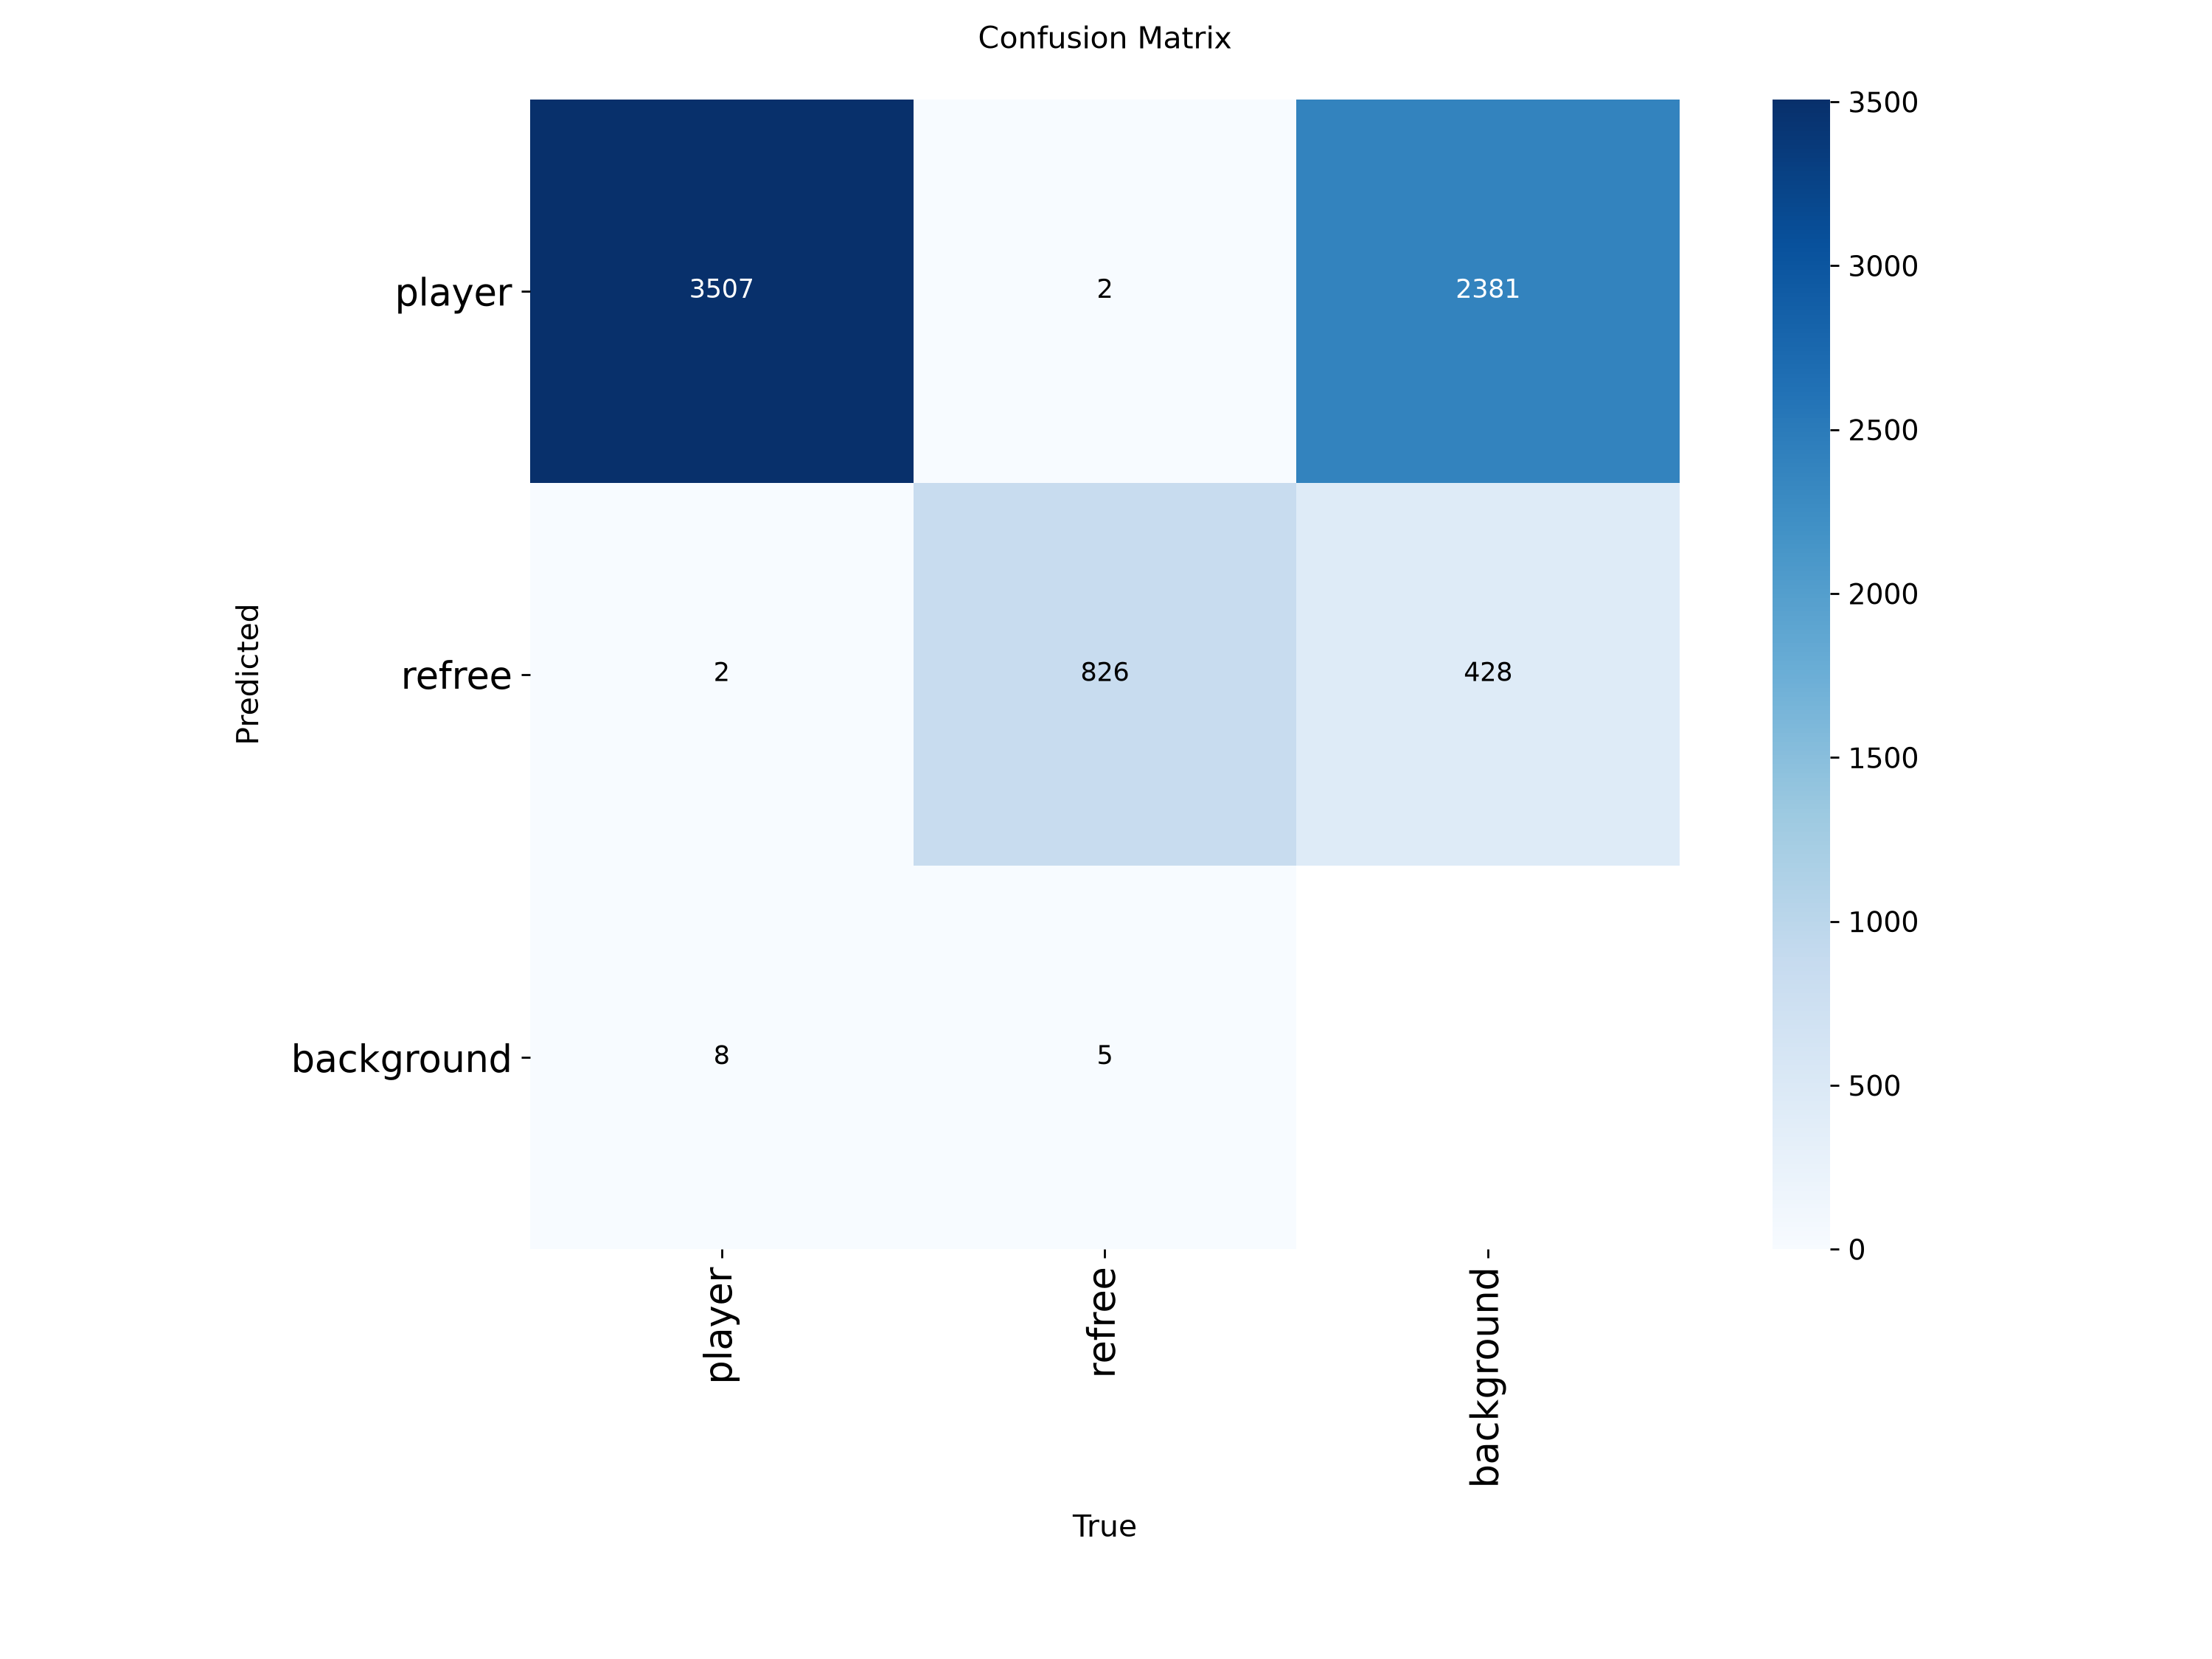

Grafico non generato da questa configurazione: PR_curve.png
C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\runs\volleyball_players\evaluation_test\confusion_matrix.png


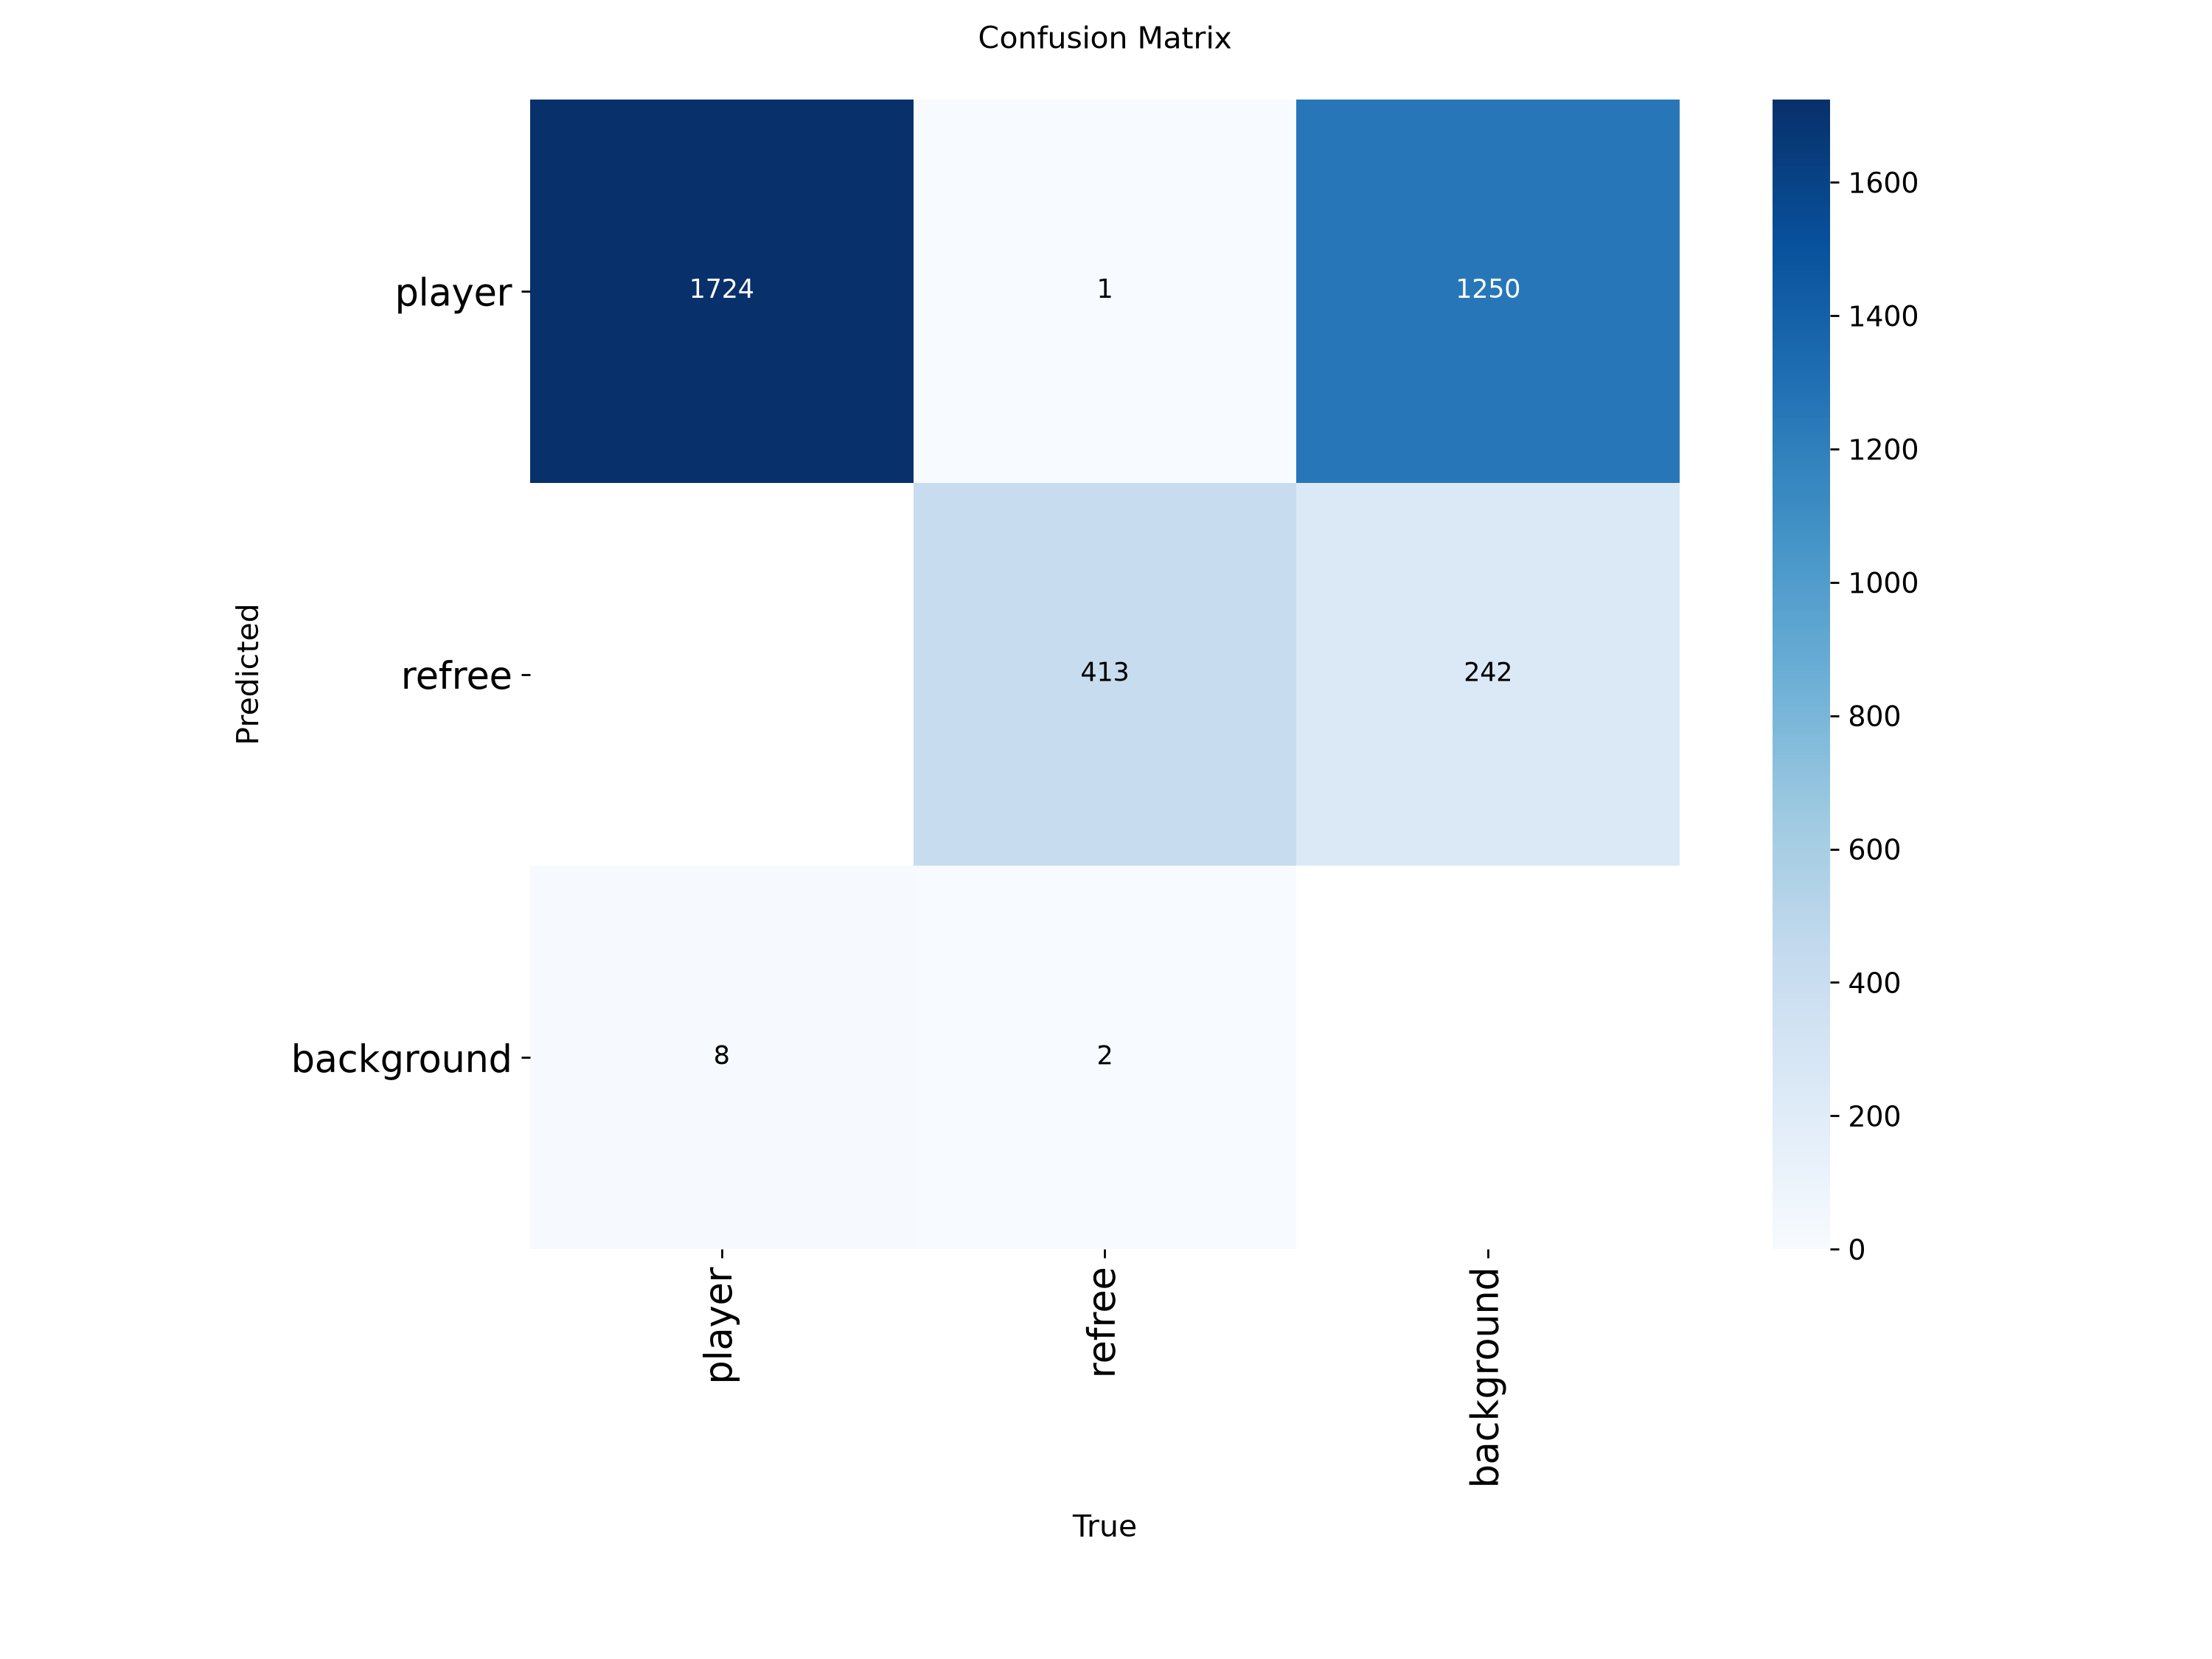

Best checkpoint: C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\runs\volleyball_players\yolov8m_players_20261117_083439\weights\best.pt
Metriche: C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\runs\volleyball_players\yolov8m_players_20261117_083439\metriche_detection_per_classe.csv
Configurazione: C:\Users\SavarDar\OneDrive - Electrolux\Desktop\Scout_Volley_CV&NLP\runs\volleyball_players\yolov8m_players_20261117_083439\configurazione_giocatori.json


In [12]:
from IPython.display import display, Image as DisplayImage
plot_paths = [TRAIN_RUN_DIR / "results.png",
              Path(validation_result.save_dir) / "PR_curve.png",
              Path(validation_result.save_dir) / "confusion_matrix.png"]
if test_result is not None:
    plot_paths.extend([Path(test_result.save_dir) / "PR_curve.png",
                       Path(test_result.save_dir) / "confusion_matrix.png"])
for plot_path in plot_paths:
    if plot_path.is_file():
        print(plot_path)
        display(DisplayImage(filename=str(plot_path)))
    else:
        print(f"Grafico non generato da questa configurazione: {plot_path.name}")

run_config = {
    "dataset_dir": str(DATASET_DIR), "source_data_yaml": str(DATASET_DIR / DATA_YAML_NAME),
    "dataset_yaml_used": str(DATA_YAML), "class_names_original": CLASS_NAMES,
    "player_class_name": CLASS_NAMES[player_ids[0]], "player_class_id": player_ids[0],
    "test_evaluated": TEST_VALID, "checkpoint_pretrained": str(RESOLVED_WEIGHTS),
    "pretrained_class_names": pretrained_names,
    "device": str(DEVICE), "cuda_available": CUDA_AVAILABLE,
    "torch": torch.__version__, "torchvision": torchvision.__version__,
    "epochs": EPOCHS, "patience": PATIENCE, "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE, "workers": WORKERS, "seed": SEED,
    "training_run_dir": str(TRAIN_RUN_DIR), "best_weights": str(BEST_WEIGHTS),
    "metrics_csv": str(METRICS_CSV),
    "scope": "object detection a classi originali; nessun single_cls, tracking, pose o riscrittura label",
}
RUN_CONFIG_PATH = TRAIN_RUN_DIR / "configurazione_giocatori.json"
RUN_CONFIG_PATH.write_text(json.dumps(run_config, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Best checkpoint: {BEST_WEIGHTS}\nMetriche: {METRICS_CSV}\nConfigurazione: {RUN_CONFIG_PATH}")